# 指標の分布の図（2026-10-15）

今井先生との 9/28 の打ち合わせを受けたメール（9/29）「今回のエクササイズではとりあえず指標の分布プロットを追加。その他の分析はデータ拡充・他指標などの目処がたってから」への対応。

これまでの報告（報告資料 2026-09-28、`docs/reports/novelty_analysis_results.md`）は、全体と組織ごとの順位の中央値だけを示していた。ここでは同じ表から、値の分布そのものを図にする。新しい計算はしない。

- 入力: `data/derived/analysis/paper_analysis.csv`、`paper_percentiles.csv`、`baseline_sample.csv`（資料の数字を出した `docs/slides/make_numbers_progress_2026-09.py` と同じ表）
- 対象: 2000年以降の論文（資料と同じ前提）
- 出力: `figures/novelty_distributions/`
  - `fig_rank_hist_ref_team.png` … 順位の分布。分野・年・参考文献数・著者数を揃えた比較（資料8ページの条件）
  - `fig_rank_hist_field_year.png` … 順位の分布。分野・年だけを揃えた比較（資料9ページの条件）
  - `fig_value_hist_all.png` … 値そのものの分布。トヨタ全体と比較相手
  - `fig_value_hist_by_org.png` … 値そのものの分布。組織ごとと比較相手
  - `rank_summary.csv` … 順位の図の各パネルの件数・中央値・上下4分の1の割合
- 最後のセルで、図に書いた中央値が資料7ページ・8ページの数字と一致することを確かめる

注: リポジトリ内のデータでは組織名を「トヨタ自動車未来創成センター」と書いているが、正式名称は「未来創生センター」。図では正式名称を使う。


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

# リポジトリの最上位（AGENTS.md がある場所）を探す
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "AGENTS.md").exists())
DD = ROOT / "data" / "derived" / "analysis"
FIG = ROOT / "figures" / "novelty_distributions"
FIG.mkdir(parents=True, exist_ok=True)

YEAR_FROM = 2000  # 資料と同じ前提

# データ内の組織名 → 図に書く名前（正式名称）
ORGS = {"豊田中央研究所": "豊田中央研究所",
        "トヨタ自動車未来創成センター": "未来創生センター",
        "AISIN IMRA(日本・aisin.com)": "AISIN IMRA（日本）",
        "AISIN IMRA(米国・imra.com)": "AISIN IMRA（米国）"}

# 指標: (列の接頭辞, 図に書く名前, 順位の向きを反転するか)
# 非慣習性は SciSciNet の値が低いほど珍しい組み合わせを含むので、順位は 100 から引いて
# 「高いほど珍しい」に向きを揃える（資料と同じ扱い）
METRICS = [("ss_novelty", "非慣習性", True), ("ss_conventionality", "定石らしさ", False),
           ("ss_disruption", "破壊性", False), ("ss_c10", "10年被引用", False)]
DIRECTION = {"ss_novelty": "（高いほど珍しい組み合わせ）", "ss_conventionality": "（高いほど定石の組み合わせ）",
             "ss_disruption": "（高いほど流れを断ち切る）", "ss_c10": "（高いほど多く引用）"}

a = pd.read_csv(DD / "paper_analysis.csv")      # 論文1件1行。SciSciNet の値と説明変数
p = pd.read_csv(DD / "paper_percentiles.csv")   # 一般論文の中での順位（0〜100）。n_refs は参考文献数
smp = pd.read_csv(DD / "baseline_sample.csv")   # 比較相手の一般論文（分野・年ごとに無作為に最大3,000件）

# 資料の数字を出したスクリプトと同じ手順で表を作る
d = p.merge(a[["paper_uid", "source_org", "ss_team_size",
               "ss_novelty", "ss_conventionality", "ss_disruption", "ss_c10"]], on="paper_uid", how="left")
d = d[d["year"] >= YEAR_FROM].copy()
cells = d[["field_id", "year"]].drop_duplicates()
base = smp.merge(cells, on=["field_id", "year"])  # トヨタの論文と同じ分野・年の一般論文
print(len(d), "件（トヨタ、2000年以降）", len(base), "件（比較相手）", len(cells), "通りの分野・年")

# SciSciNet の zスコアには無限大（inf）の論文がある。値そのものの図では欠損として扱う（順位の列には影響しない）
SS_COLS = ["ss_novelty", "ss_conventionality", "ss_disruption", "ss_c10"]
for name, df in [("トヨタ", d), ("比較相手", base)]:
    n_inf = {c: int(np.isinf(df[c]).sum()) for c in SS_COLS}
    print(name, "の無限大の件数:", n_inf)
    df[SS_COLS] = df[SS_COLS].replace([np.inf, -np.inf], np.nan)

plt.rcParams.update({"font.family": "Hiragino Sans", "font.size": 10, "axes.titlesize": 11})
GRAY, INK = "#b0b0b0", "#333333"


624 件（トヨタ、2000年以降） 432000 件（比較相手） 144 通りの分野・年
トヨタ の無限大の件数: {'ss_novelty': 0, 'ss_conventionality': 0, 'ss_disruption': 0, 'ss_c10': 0}
比較相手 の無限大の件数: {'ss_novelty': 395, 'ss_conventionality': 2232, 'ss_disruption': 0, 'ss_c10': 0}


## 順位の分布

順位は、その論文と同じ分野・同じ年（条件によってはさらに参考文献数・著者数も近い）の一般論文の中で、何パーセントの位置にあるかを 0〜100 で表した値（50 が真ん中）。報告資料と同じ値（`paper_percentiles.csv`）をそのまま使う。

トヨタの論文が一般論文と同じ分布なら、順位は 0〜100 に一様に散るので、10 刻みの各区間に 10% ずつ入る。図の破線はその高さ。棒が破線より高い区間に論文が偏っている。

比べる相手が30件未満の論文は順位が無い（資料と同じ）。そのため、条件を増やした図のほうが件数が少し減る。


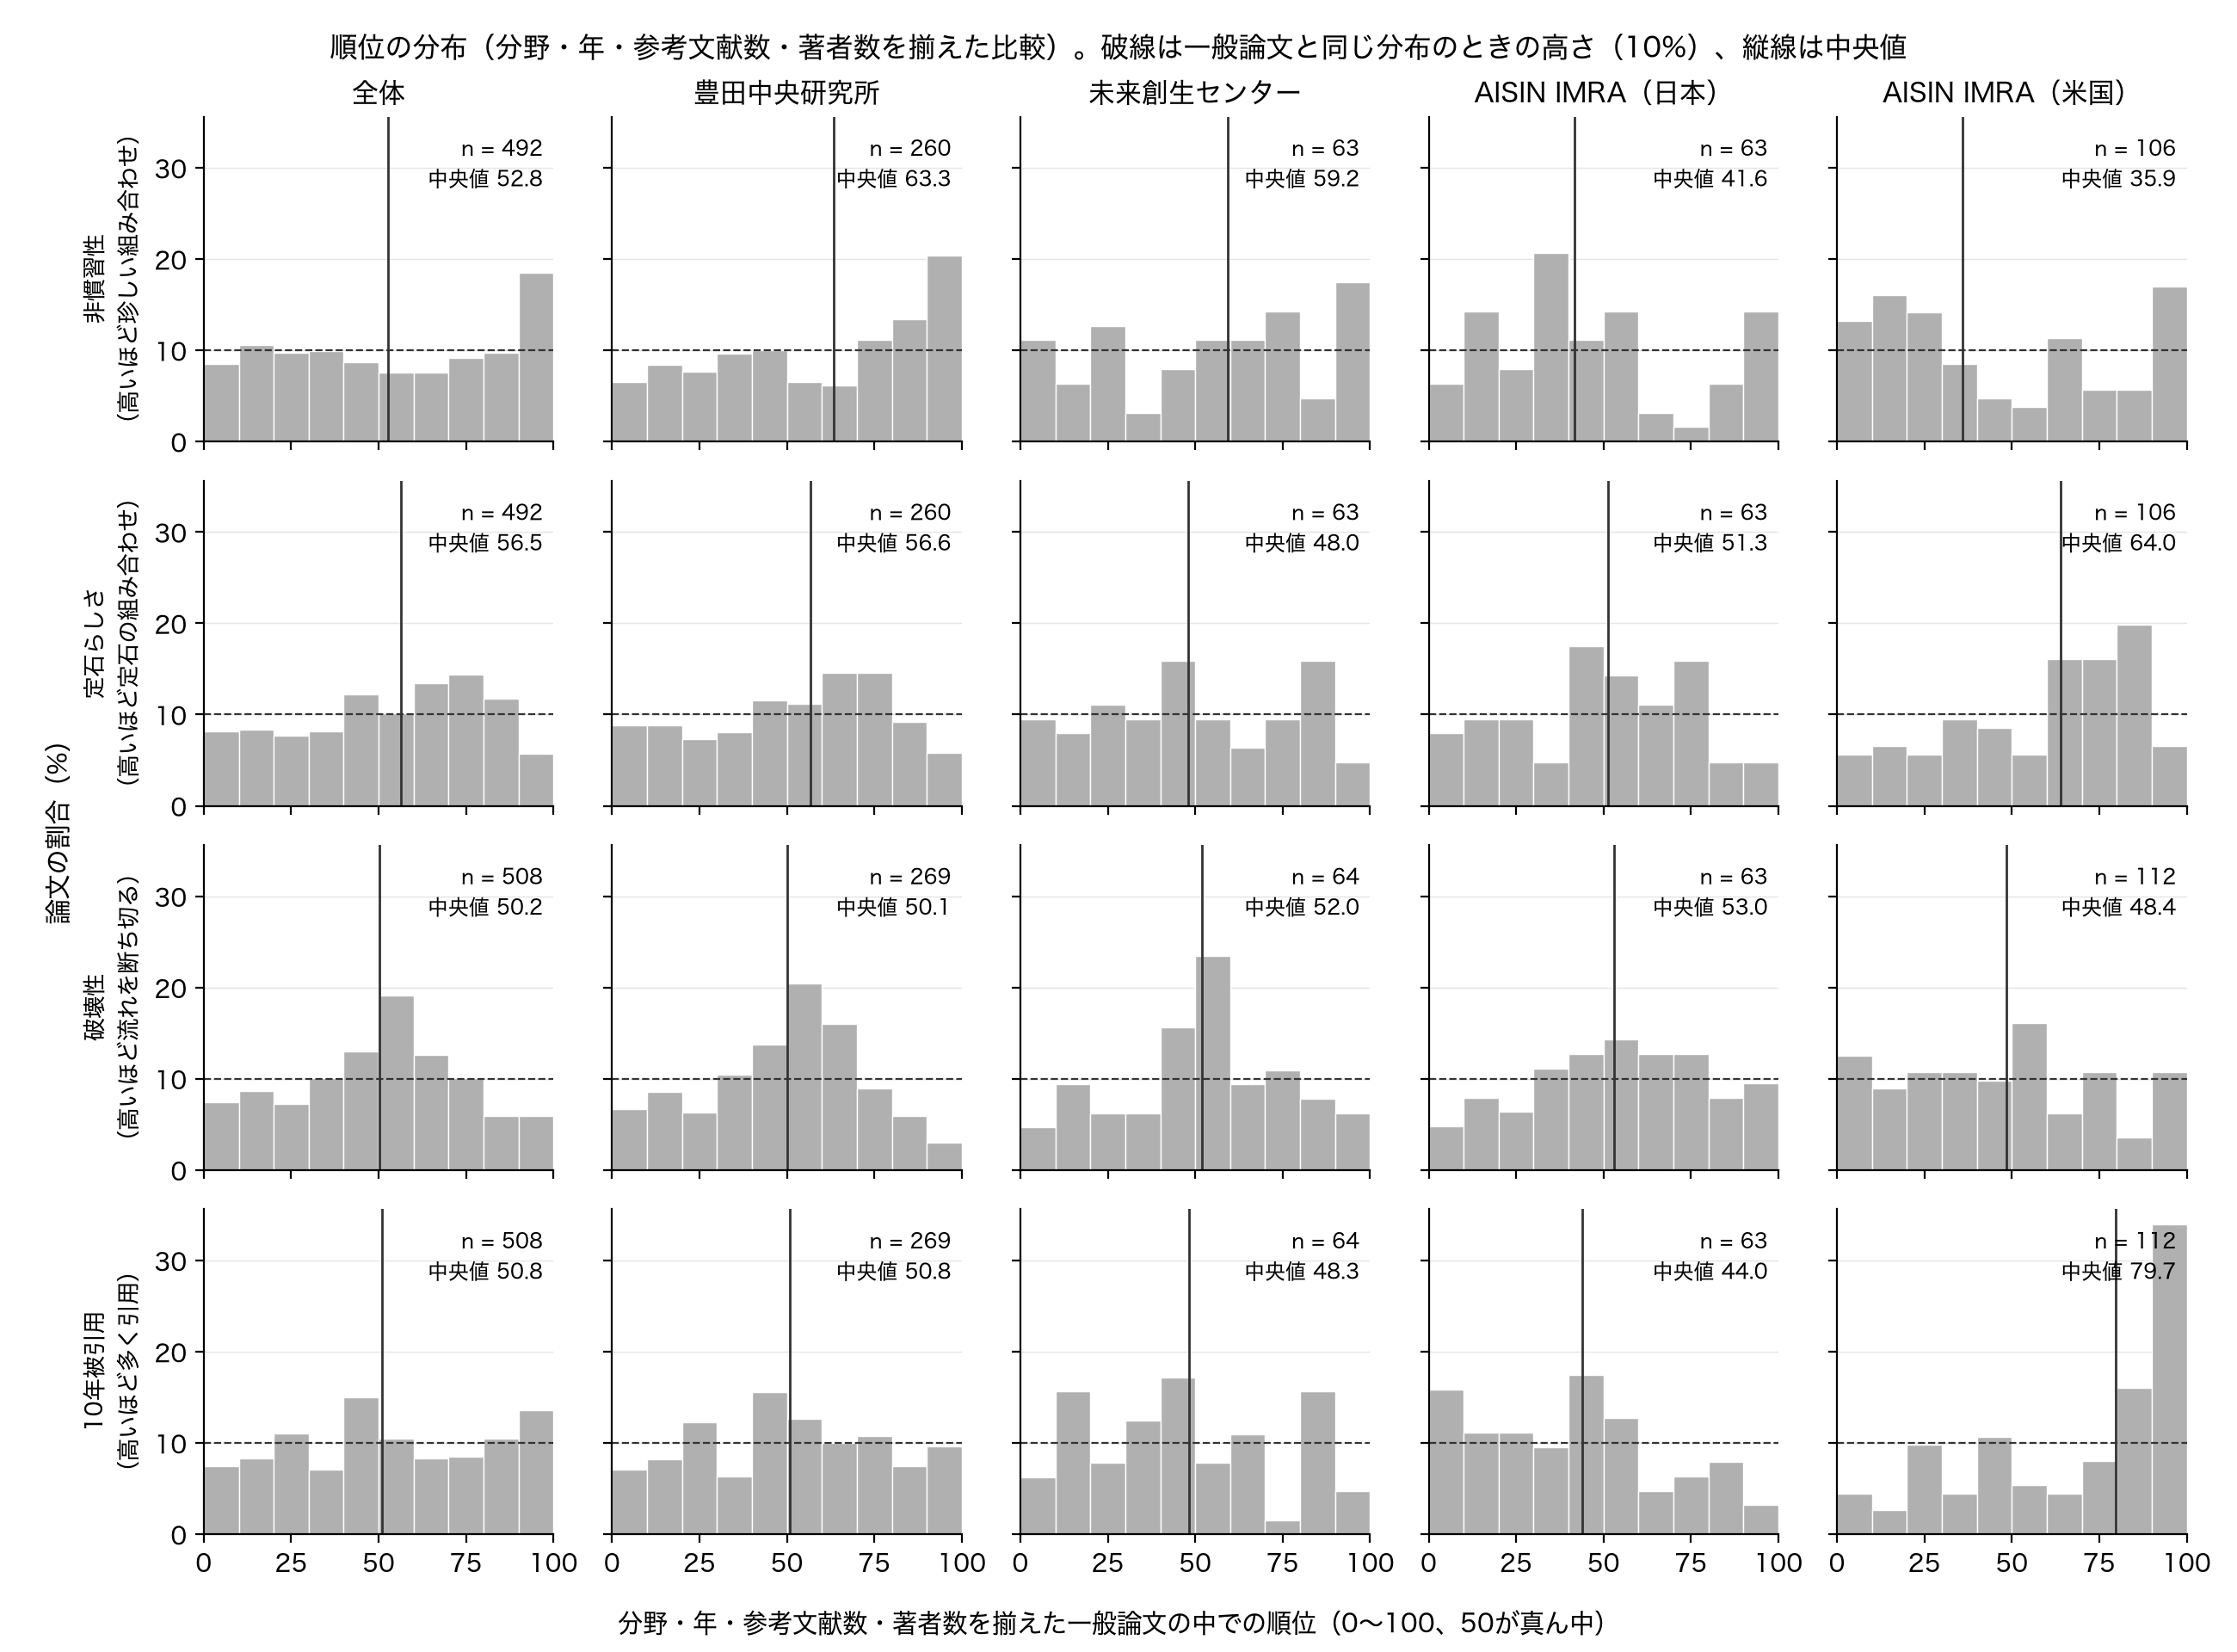

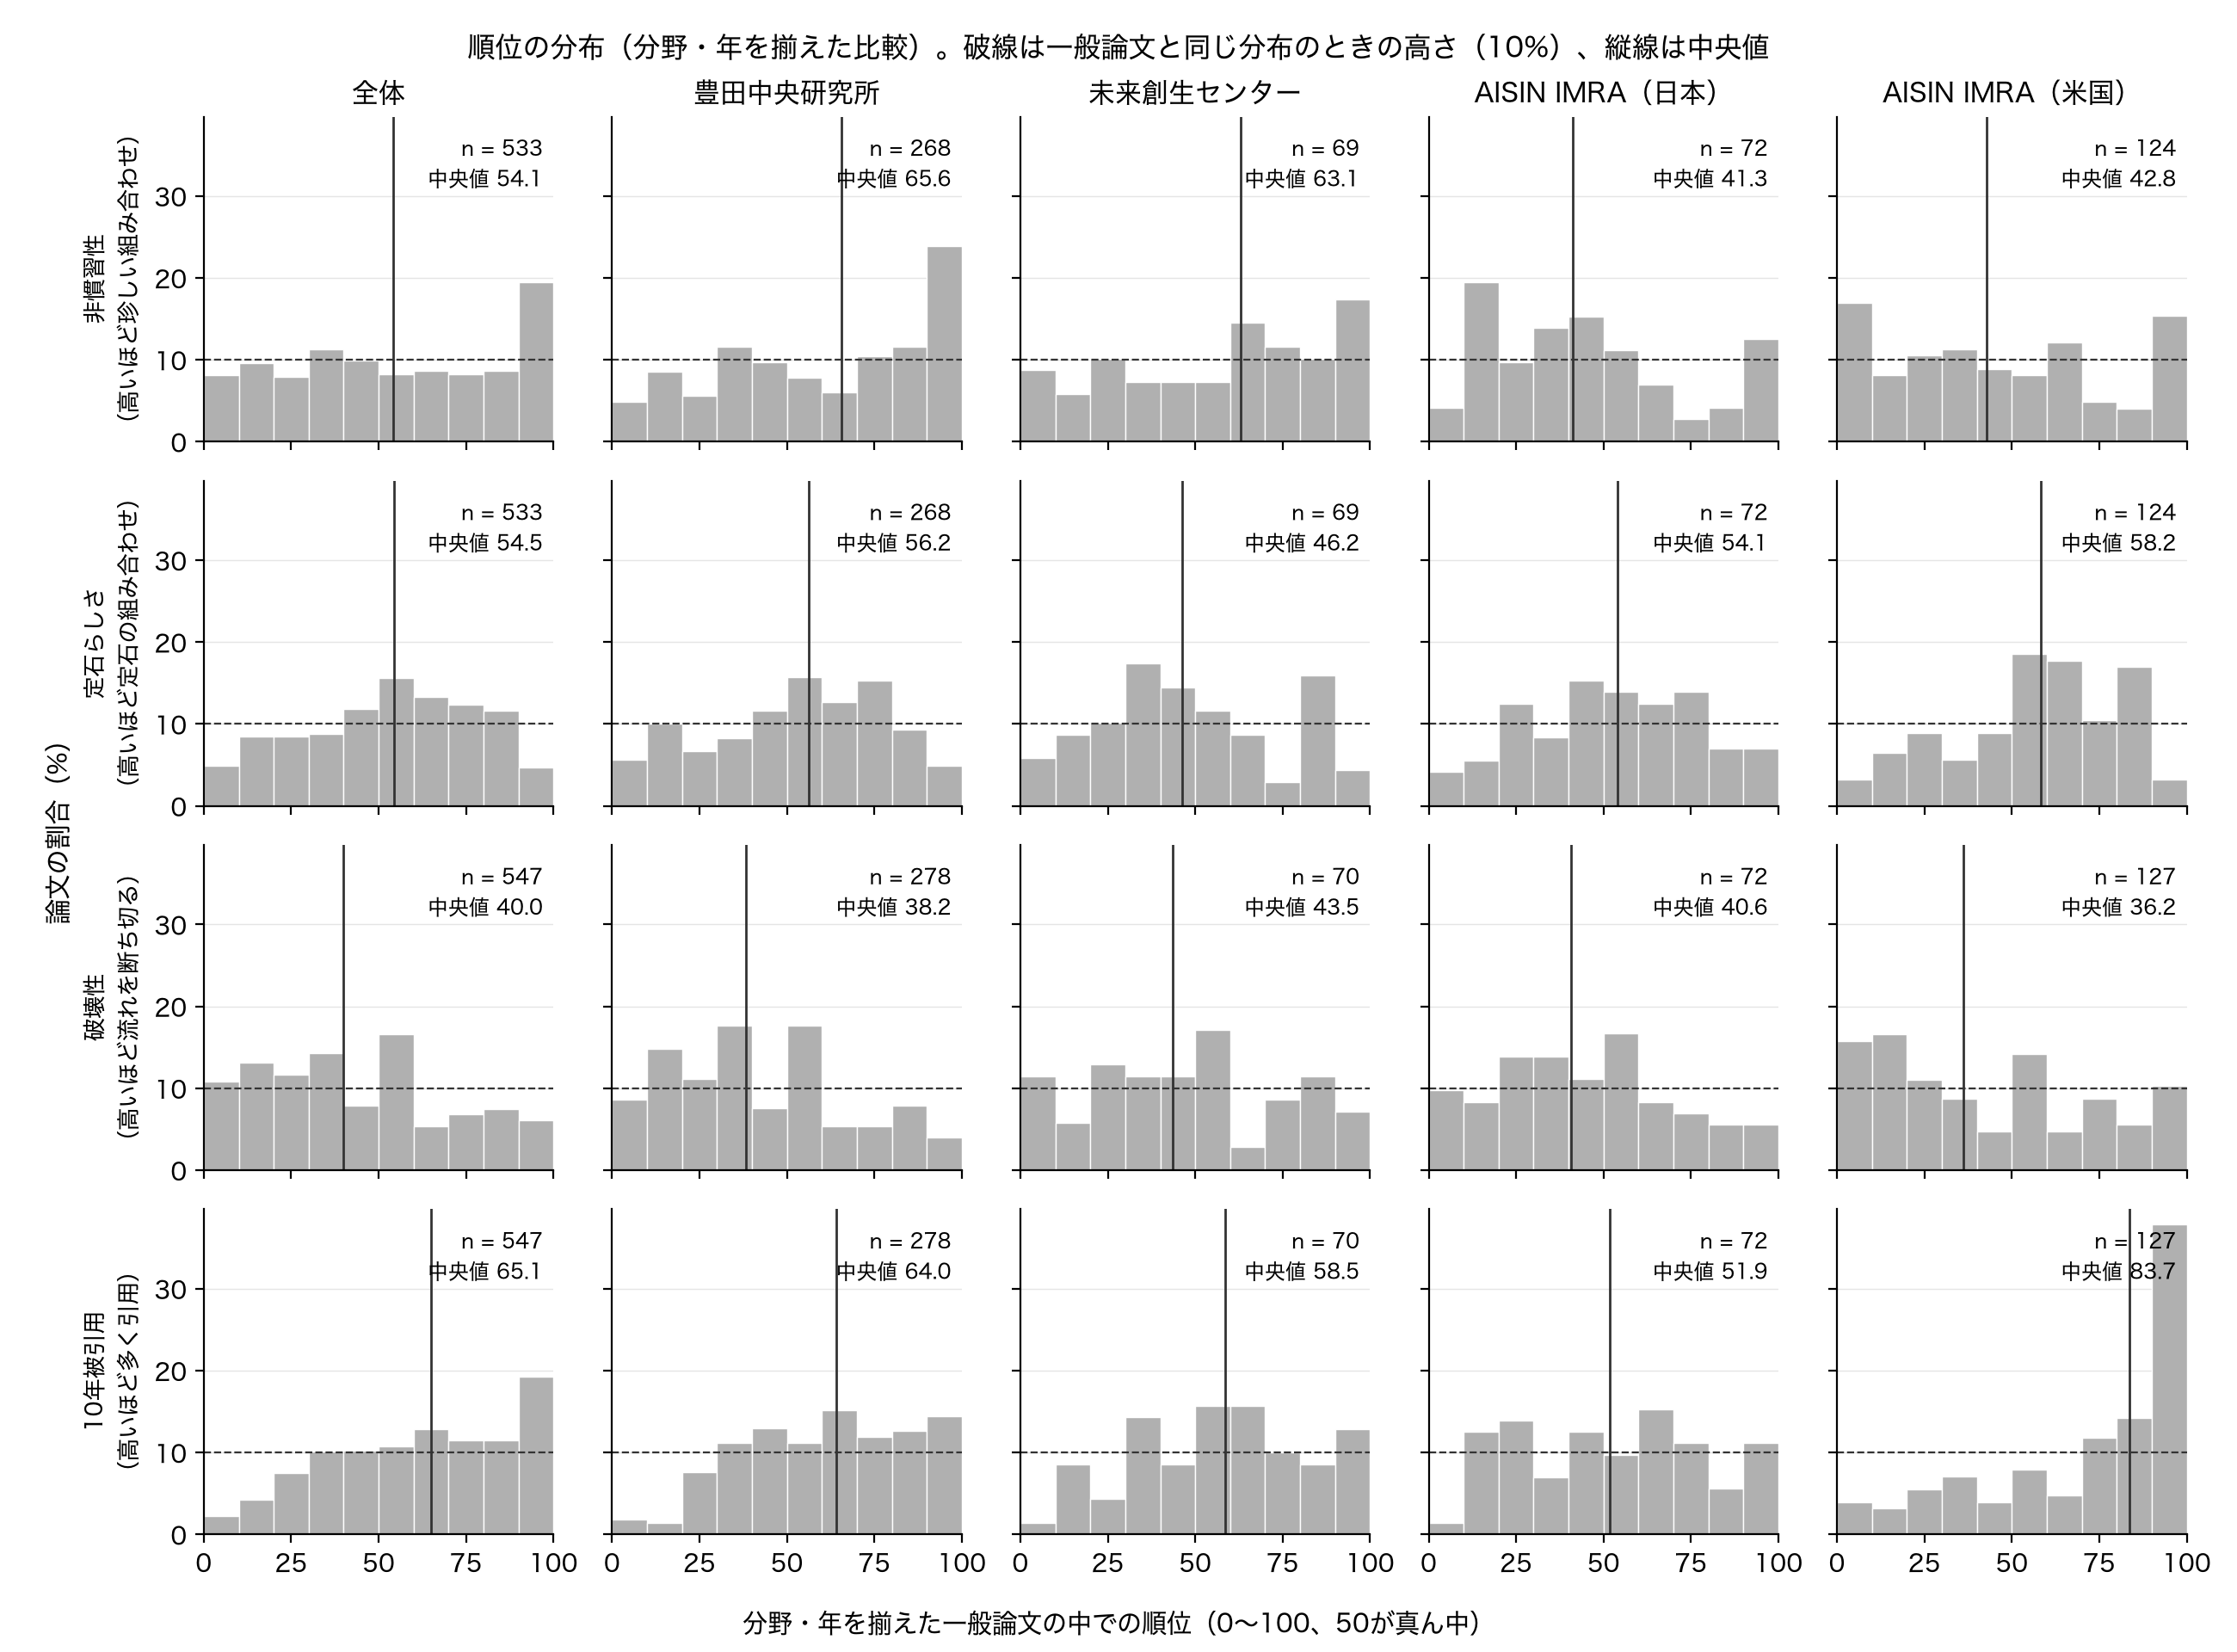

,条件,組織,指標,n,中央値,下位4分の1（25以下）の割合%,上位4分の1（75以上）の割合%
0,分野・年・参考文献数・著者数,全体,非慣習性,492,52.8,23.6,32.7
1,分野・年・参考文献数・著者数,豊田中央研究所,非慣習性,260,63.3,17.7,39.2
2,分野・年・参考文献数・著者数,未来創生センター,非慣習性,63,59.2,22.2,30.2
3,分野・年・参考文献数・著者数,AISIN IMRA（日本）,非慣習性,63,41.6,23.8,22.2
4,分野・年・参考文献数・著者数,AISIN IMRA（米国）,非慣習性,106,35.9,38.7,24.5
5,分野・年・参考文献数・著者数,全体,定石らしさ,492,56.5,20.7,26.2
6,分野・年・参考文献数・著者数,豊田中央研究所,定石らしさ,260,56.6,21.5,24.2
7,分野・年・参考文献数・著者数,未来創生センター,定石らしさ,63,48.0,22.2,25.4
8,分野・年・参考文献数・著者数,AISIN IMRA（日本）,定石らしさ,63,51.3,22.2,17.5
9,分野・年・参考文献数・著者数,AISIN IMRA（米国）,定石らしさ,106,64.0,17.0,36.8


In [2]:
def rank_hist(suffix: str, cond: str, fname: str) -> pd.DataFrame:
    # 順位の分布を、指標（行）× 組織（列）の小さな図に並べて描く。
    # suffix は paper_percentiles.csv の列の接尾辞（"" = 分野・年、"_ref_team" = 分野・年・参考文献数・著者数）。
    # 戻り値は各パネルの件数・中央値・下位4分の1と上位4分の1の割合。
    groups = [("全体", d)] + [(lab, d[d["source_org"] == org]) for org, lab in ORGS.items()]
    edges = np.arange(0, 101, 10)
    rows = []
    fig, axes = plt.subplots(len(METRICS), len(groups), figsize=(13, 9.6), dpi=200, sharex=True, sharey=True)
    for i, (m, mlab, flip) in enumerate(METRICS):
        for j, (glab, g) in enumerate(groups):
            ax = axes[i, j]
            v = g[f"{m}_pct{suffix}"].dropna()
            if flip:
                v = 100 - v
            share = np.histogram(v, bins=edges)[0] / len(v) * 100  # 各区間に入る論文の割合（%）
            ax.bar((edges[:-1] + edges[1:]) / 2, share, width=10, color=GRAY, edgecolor="white", linewidth=0.5)
            ax.axhline(10, color=INK, ls="--", lw=0.8)  # 一般論文と同じ分布なら各区間に10%ずつ入る
            med = float(v.median())
            ax.axvline(med, color=INK, lw=1.0)
            ax.text(0.97, 0.95, f"n = {len(v)}\n中央値 {med:.1f}", transform=ax.transAxes,
                    ha="right", va="top", fontsize=8.5)
            ax.set_xlim(0, 100)
            ax.set_xticks([0, 25, 50, 75, 100])
            ax.grid(axis="y", color="#e5e5e5", lw=0.5)
            ax.set_axisbelow(True)
            for s in ("top", "right"):
                ax.spines[s].set_visible(False)
            if i == 0:
                ax.set_title(glab)
            if j == 0:
                ax.set_ylabel(mlab + "\n" + DIRECTION[m], fontsize=9.5)
            rows.append({"条件": cond, "組織": glab, "指標": mlab, "n": len(v), "中央値": round(med, 1),
                         "下位4分の1（25以下）の割合%": round(float((v <= 25).mean() * 100), 1),
                         "上位4分の1（75以上）の割合%": round(float((v >= 75).mean() * 100), 1)})
    ymax = max(ax.get_ylim()[1] for ax in axes.flat)
    axes[0, 0].set_ylim(0, ymax)
    fig.supxlabel(f"{cond}を揃えた一般論文の中での順位（0〜100、50が真ん中）", fontsize=10.5)
    fig.supylabel("論文の割合（%）", fontsize=10.5)
    fig.suptitle(f"順位の分布（{cond}を揃えた比較）。破線は一般論文と同じ分布のときの高さ（10%）、縦線は中央値",
                 fontsize=11.5)
    fig.tight_layout()
    fig.savefig(FIG / fname, facecolor="white")
    plt.close(fig)
    display(Image(str(FIG / fname), width=1000))
    return pd.DataFrame(rows)


summ_both = rank_hist("_ref_team", "分野・年・参考文献数・著者数", "fig_rank_hist_ref_team.png")
summ_fy = rank_hist("", "分野・年", "fig_rank_hist_field_year.png")
summary = pd.concat([summ_both, summ_fy], ignore_index=True)
summary.to_csv(FIG / "rank_summary.csv", index=False, encoding="utf-8-sig")
summary


## 値そのものの分布

順位ではなく SciSciNet の値そのものを、トヨタの論文と比較相手の一般論文で重ねて描く。

- **比較相手の重み付け。** 比較相手は分野・年ごとに最大3,000件ずつ引いてあるので、そのまま重ねるとトヨタの論文が1件しかない分野・年も、100件ある分野・年と同じ重さで入る。そこで分野・年ごとに「トヨタの件数 ÷ 比較相手の件数」の重みを付け、分野・年の構成をトヨタの論文と同じにしてから描く。
- **横軸の変換。** zスコアは数千に達する論文があるので、符号を保ったまま対数的に縮める（±10 までは線形に近い）。破壊性は大半が ±0.01 の中に集まるので、同じ縮め方を ±0.001 を基準にして使う。被引用と参考文献数は 1 を足して対数にする。目盛りには元の値を書く。
- **無限大の値。** SciSciNet の zスコアには無限大の論文がある（件数は上のセルの出力）。値そのものの図では欠損として扱う。順位は元の表の値をそのまま使っているので影響しない。
- **破壊性の 0。** SciSciNet v2 は引用されていない論文に 0 を入れているとみられる（2026-09-28 のログ）。ちょうど 0 の論文の割合をパネルに書く。
- **著者数の 0。** SciSciNet の著者の記録が欠けている論文（2024年に多い）。直さずそのまま描く（2026-10-14 の判断）。20人以上は 20 にまとめる。
- 縦軸は論文の相対的な多さ（面積が 1 になるようにした密度）。目盛りの数字に意味がないので消してある。


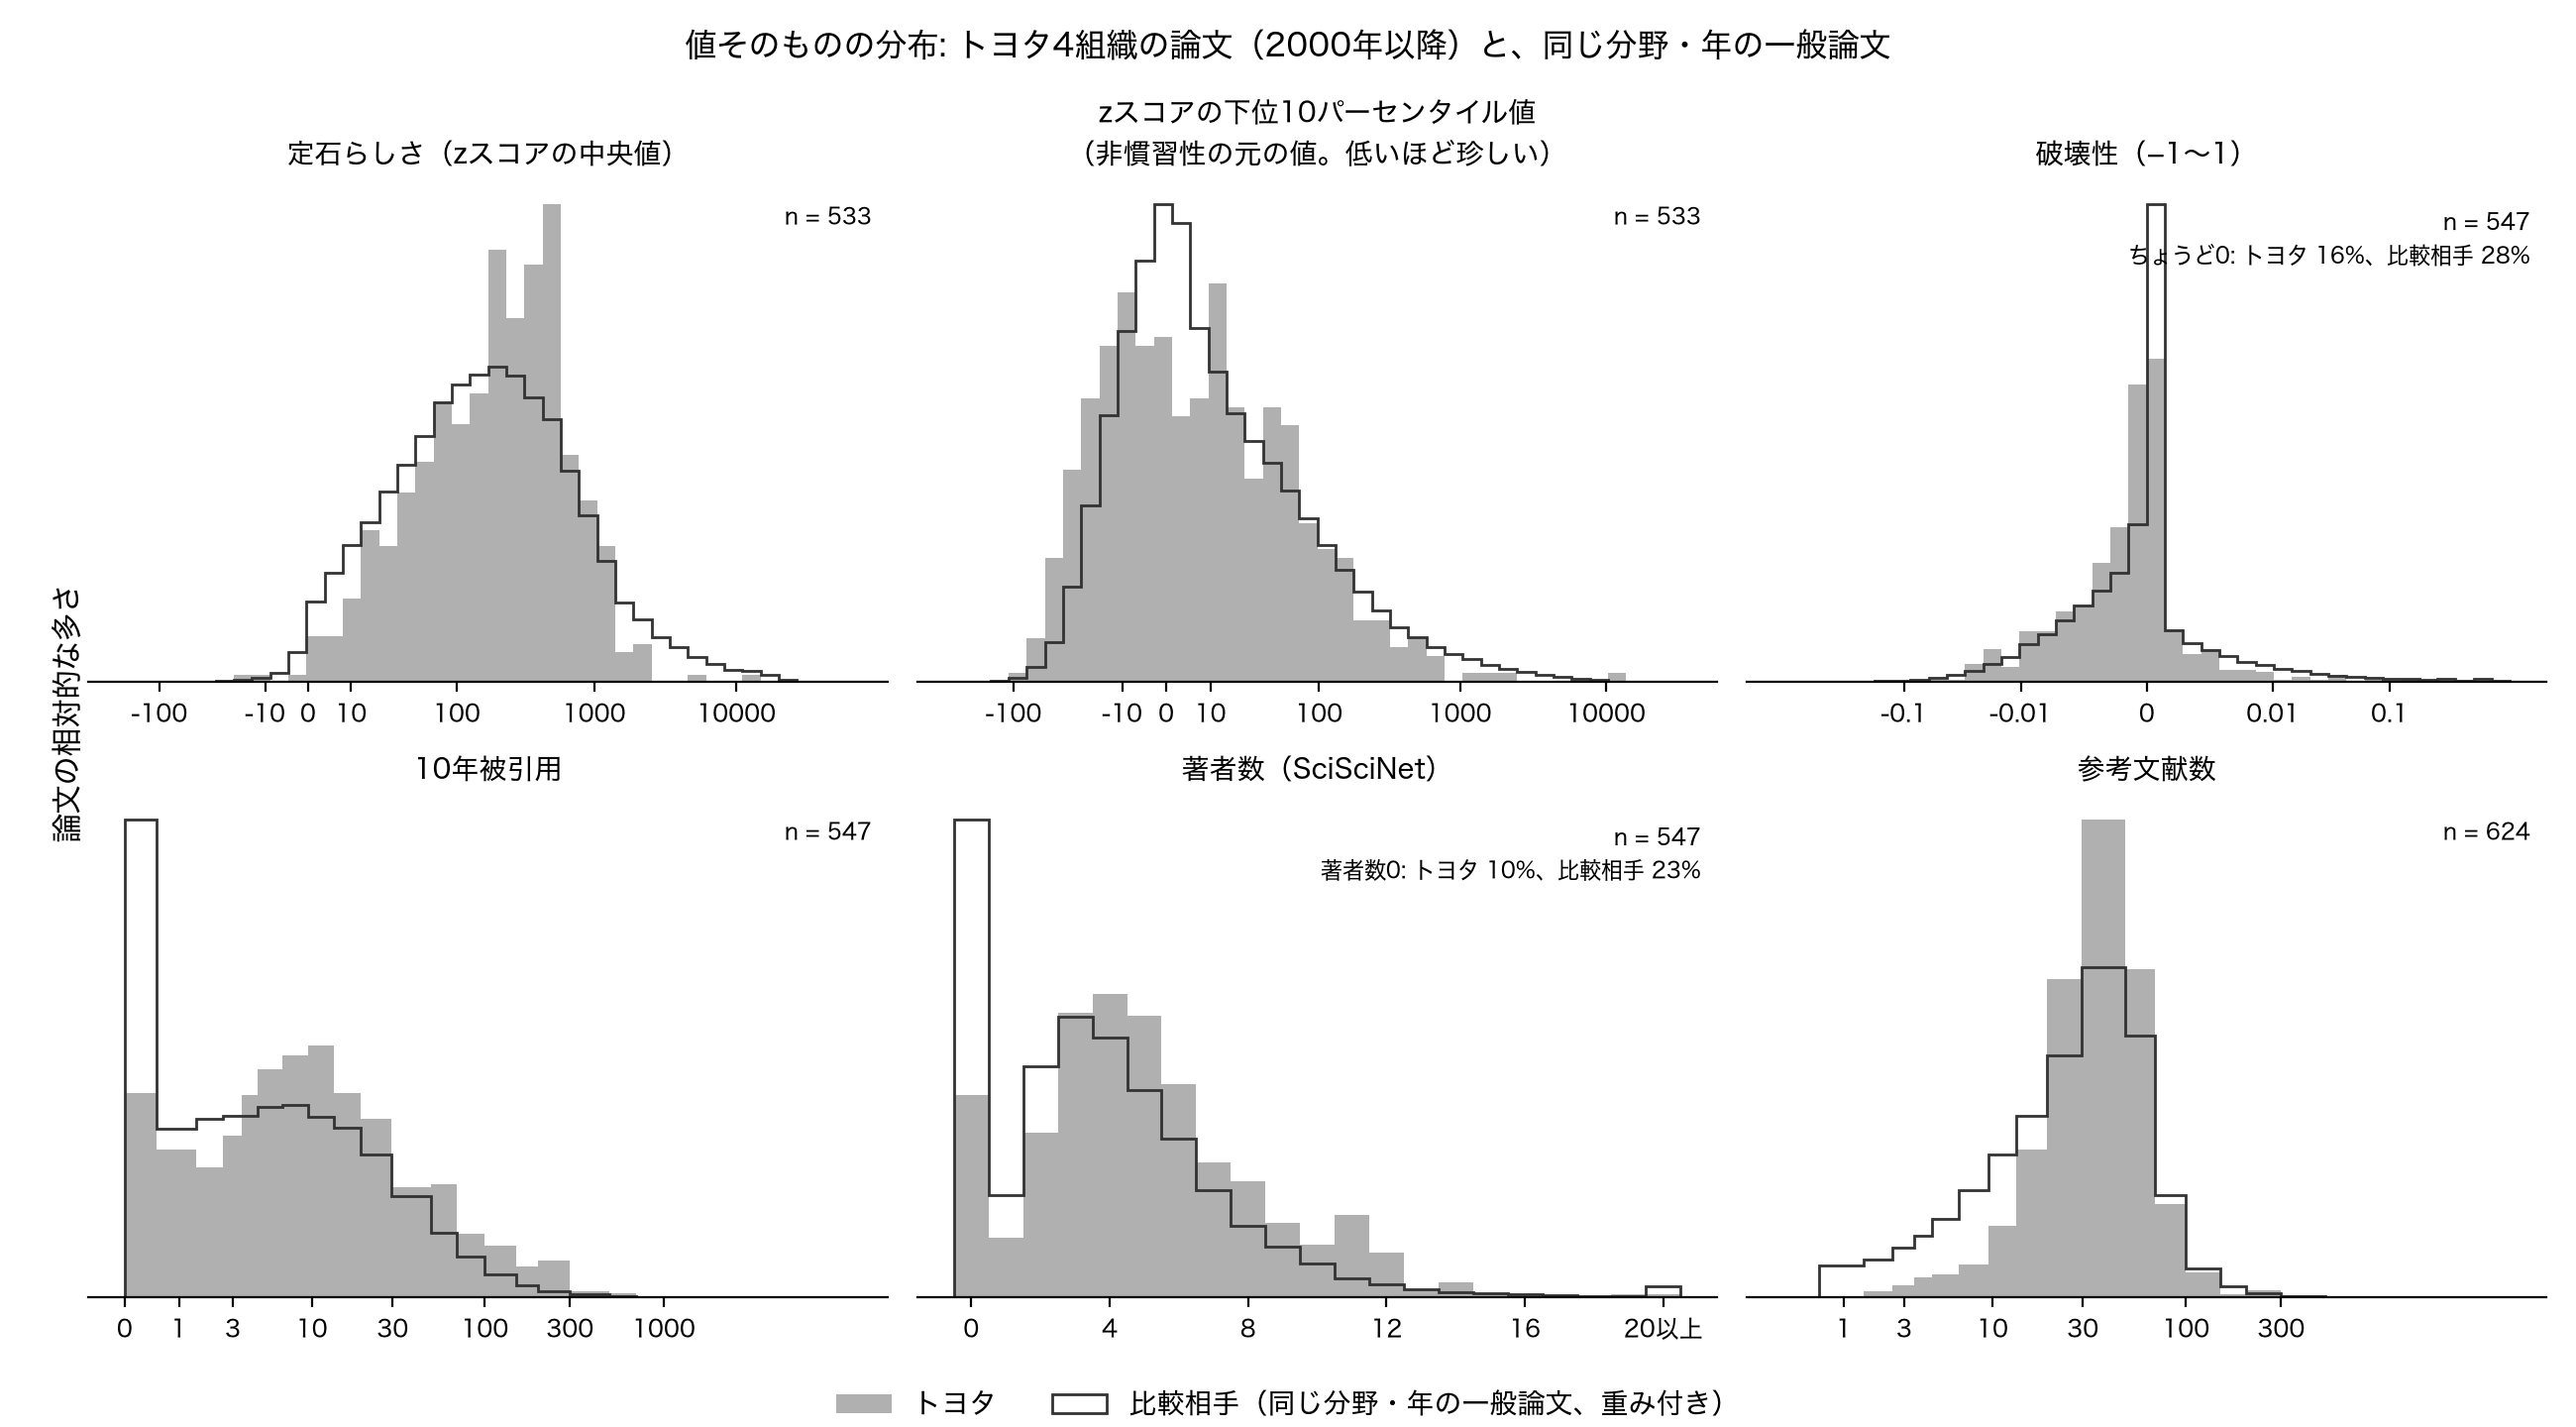

In [3]:
def weighted_base(g: pd.DataFrame, col: str):
    # 比較相手の値と重みを返す。重みは分野・年ごとに「トヨタの件数 ÷ 比較相手の件数」。
    # 値が欠けている論文は、トヨタ側・比較相手側ともに数えない。
    t = g.dropna(subset=[col]).groupby(["field_id", "year"]).size().rename("n_t")
    b = base.dropna(subset=[col]).merge(t, left_on=["field_id", "year"], right_index=True, how="inner")
    n_b = b.groupby(["field_id", "year"])[col].transform("size")
    return b[col].to_numpy(), (b["n_t"] / n_b).to_numpy()


def symlog(x, lin):
    # 符号を保ったまま対数的に縮める。|x| が lin までは線形に近く、それより大きいと対数になる
    x = np.asarray(x, dtype=float)
    return np.sign(x) * np.log10(1 + np.abs(x) / lin)


def log1(x):
    return np.log10(1 + np.asarray(x, dtype=float))


def cap20(x):
    return np.minimum(np.asarray(x, dtype=float), 20)


# (列, 図に書く名前, 横軸の変換, 目盛りに書く元の値)
VALUES = [
    ("ss_conventionality", "定石らしさ（zスコアの中央値）", lambda x: symlog(x, 10), [-100, -10, 0, 10, 100, 1000, 10000]),
    ("ss_novelty", "zスコアの下位10パーセンタイル値\n（非慣習性の元の値。低いほど珍しい）", lambda x: symlog(x, 10), [-100, -10, 0, 10, 100, 1000, 10000]),
    ("ss_disruption", "破壊性（−1〜1）", lambda x: symlog(x, 0.001), [-0.1, -0.01, 0, 0.01, 0.1]),
    ("ss_c10", "10年被引用", log1, [0, 1, 3, 10, 30, 100, 300, 1000]),
    ("ss_team_size", "著者数（SciSciNet）", cap20, [0, 4, 8, 12, 16, 20]),
    ("n_refs", "参考文献数", log1, [1, 3, 10, 30, 100, 300]),
]


def value_panel(ax, g: pd.DataFrame, col: str, label: str, tr, ticks, nbins: int = 40):
    raw_t = g[col].dropna().to_numpy()
    tv = tr(raw_t)
    bv, w = weighted_base(g, col)
    bt = tr(bv)
    if col == "ss_team_size":
        edges = np.arange(-0.5, 21.5, 1)  # 著者数は1人刻み
    elif col in ("ss_c10", "n_refs"):
        # 件数は整数なので、小さい値は1件刻み、大きい値はおおむね対数で等間隔の区間にする（区間の境目は整数の間）
        cuts = np.array([1, 2, 3, 4, 5, 7, 10, 14, 20, 30, 50, 70, 100, 150, 200, 300, 500, 700, 1000, 1500, 2000, 3000])
        raw_max = max(raw_t.max(), bv.max())
        raw_edges = np.concatenate([[0], cuts[cuts - 0.5 < raw_max] - 0.5, [raw_max + 0.5]])  # 0 の区間は 0〜0.5
        edges = tr(raw_edges)
    else:
        lo, hi = min(tv.min(), bt.min()), max(tv.max(), bt.max())
        edges = np.linspace(lo, hi, nbins + 1)
    ax.hist(tv, bins=edges, density=True, color=GRAY, label="トヨタ")
    # 比較相手は重み付きで、面積が 1 になるように描く
    ax.hist(bt, bins=edges, weights=w, density=True, histtype="step", color=INK, lw=1.0,
            label="比較相手（同じ分野・年の一般論文、重み付き）")
    ax.set_xticks(tr(np.array(ticks, dtype=float)))
    ax.set_xticklabels([("20以上" if col == "ss_team_size" and t == 20 else f"{t:g}") for t in ticks], fontsize=8.5)
    ax.set_yticks([])
    ax.set_title(label, fontsize=10)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    note = f"n = {len(tv)}"
    if col == "ss_disruption":
        z_t = float((g[col].dropna() == 0).mean() * 100)
        z_b = float(np.average(bv == 0, weights=w) * 100)
        note += f"\nちょうど0: トヨタ {z_t:.0f}%、比較相手 {z_b:.0f}%"
    if col == "ss_team_size":
        z_t = float((g[col].dropna() == 0).mean() * 100)
        z_b = float(np.average(bv == 0, weights=w) * 100)
        note += f"\n著者数0: トヨタ {z_t:.0f}%、比較相手 {z_b:.0f}%"
    ax.text(0.98, 0.95, note, transform=ax.transAxes, ha="right", va="top", fontsize=8)


fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), dpi=200)
for ax, (col, label, tr, ticks) in zip(axes.flat, VALUES):
    value_panel(ax, d, col, label, tr, ticks)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.supylabel("論文の相対的な多さ", fontsize=10.5)
fig.suptitle("値そのものの分布: トヨタ4組織の論文（2000年以降）と、同じ分野・年の一般論文", fontsize=11.5)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / "fig_value_hist_all.png", facecolor="white")
plt.close(fig)
display(Image(str(FIG / "fig_value_hist_all.png"), width=1000))


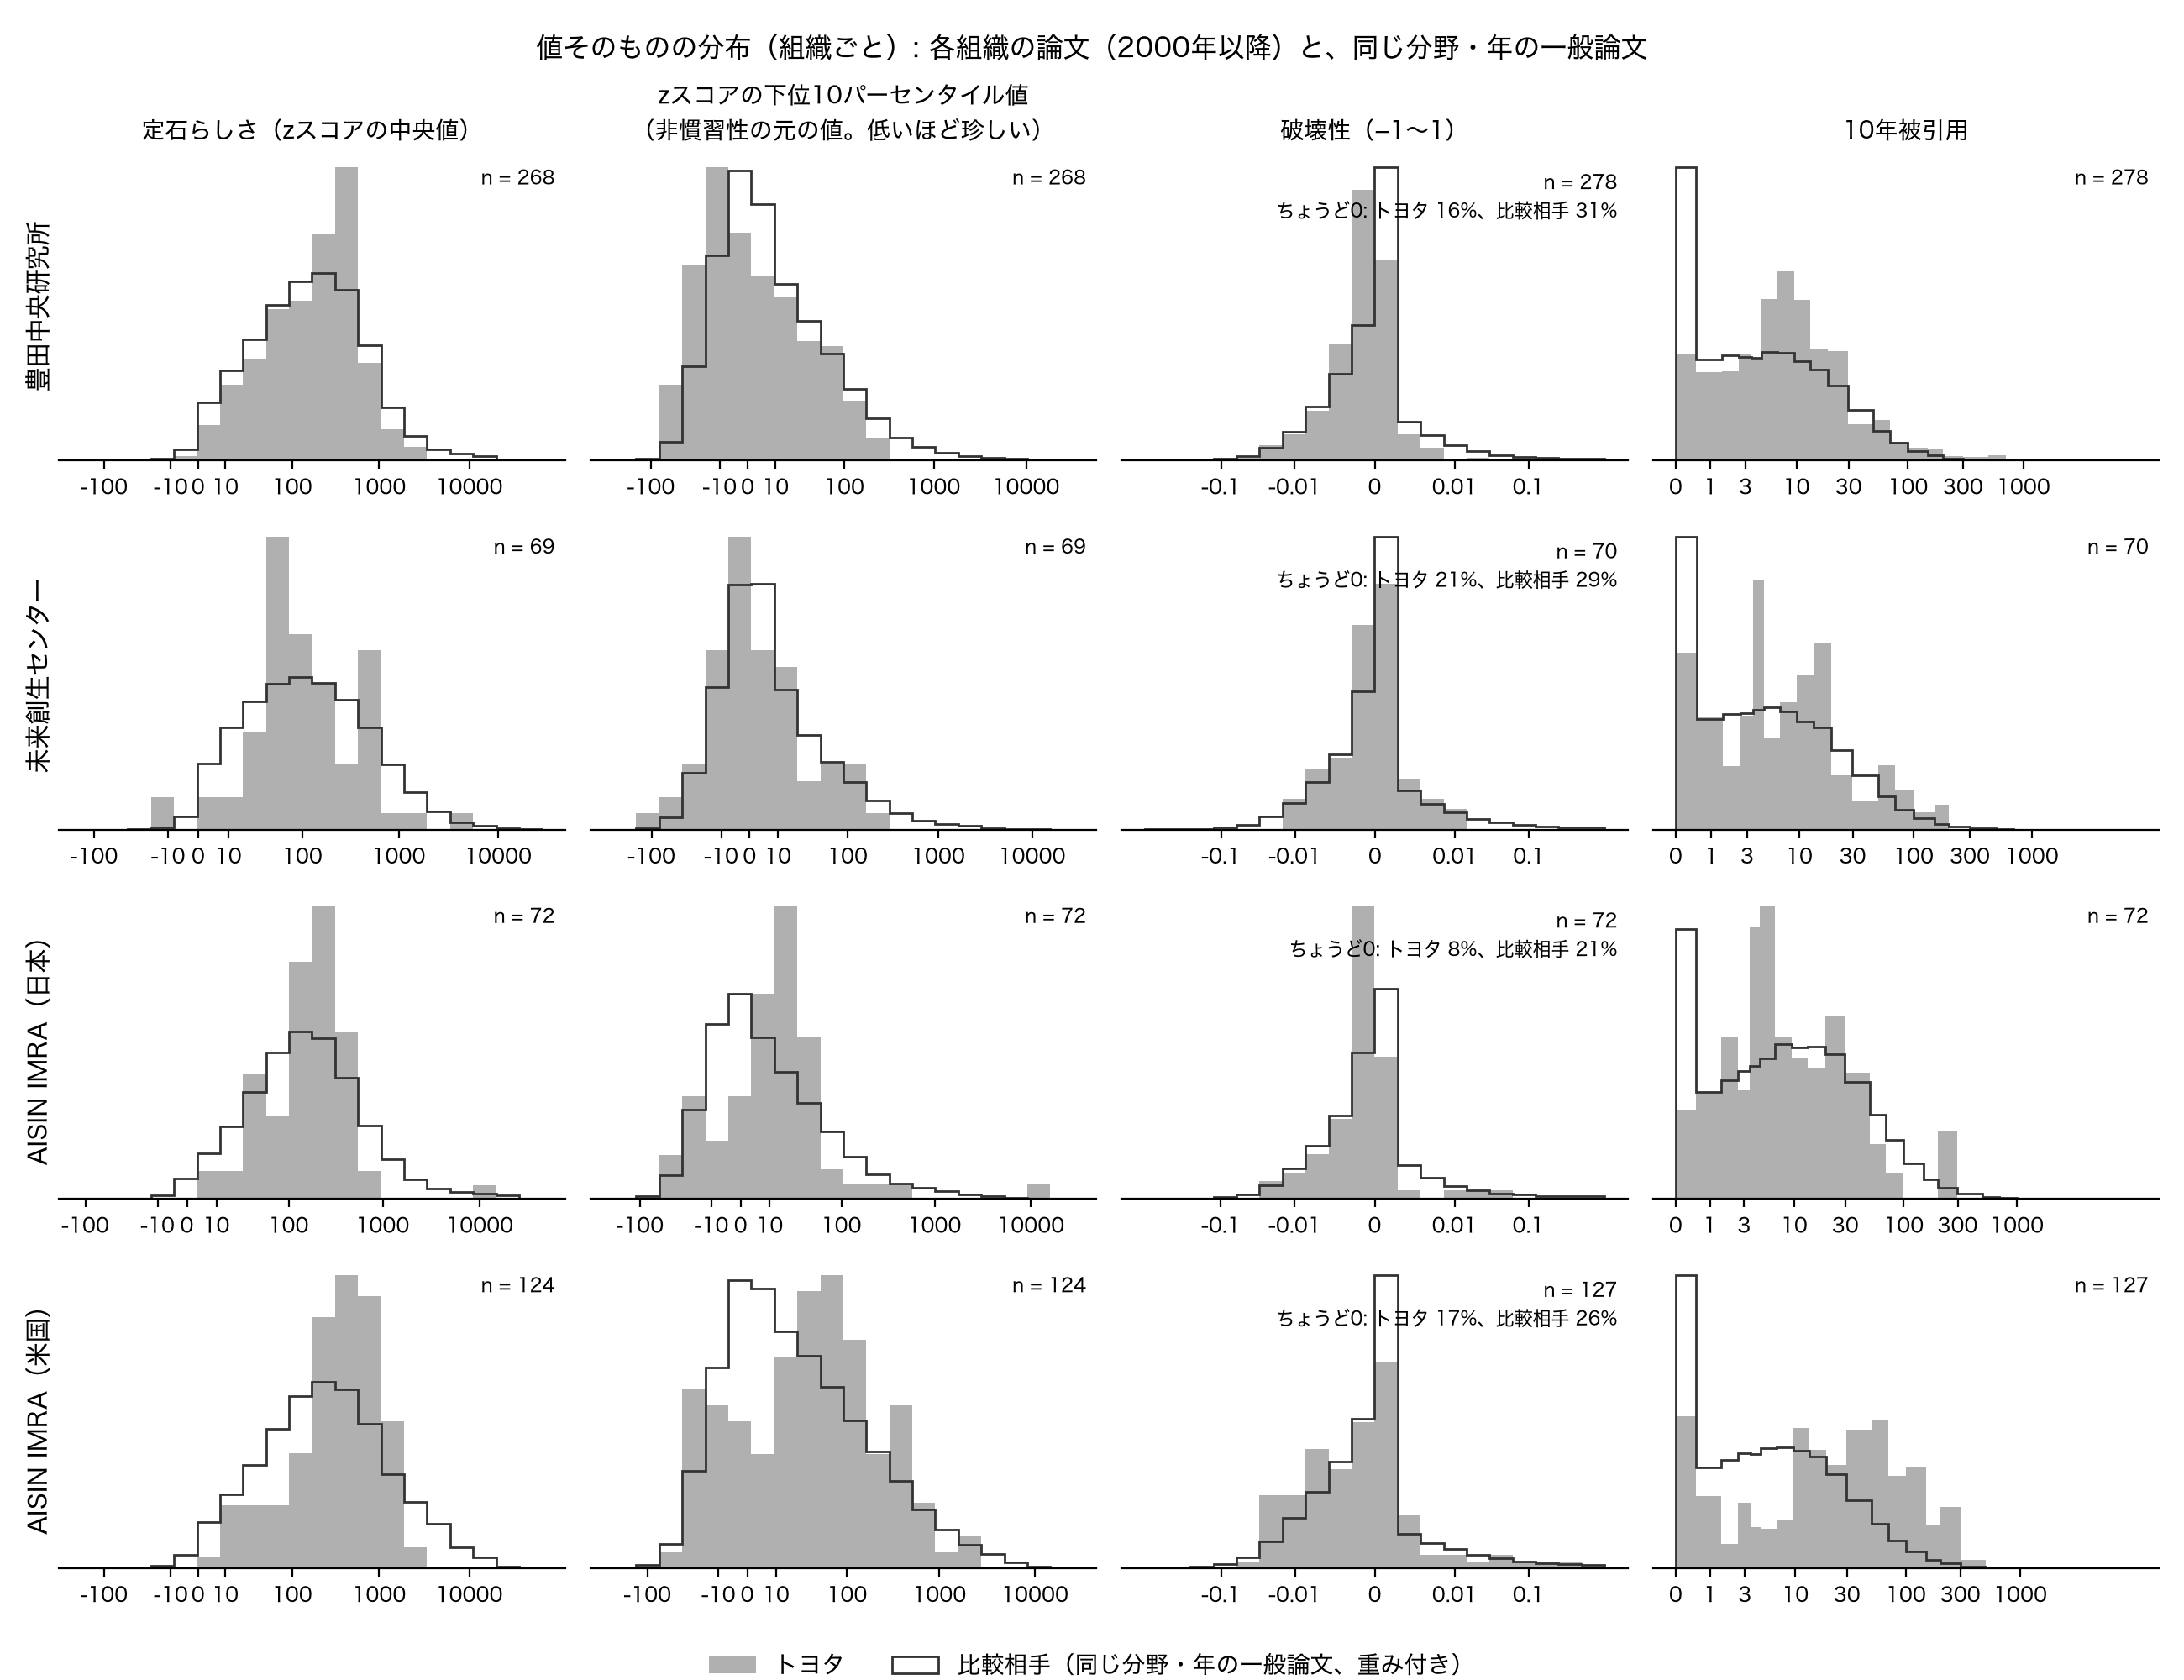

In [4]:
# 組織ごと。行が組織、列が指標。比較相手の重みは組織ごとに付け直す
cols4 = VALUES[:4]
fig, axes = plt.subplots(len(ORGS), len(cols4), figsize=(13, 10), dpi=200)
for i, (org, olab) in enumerate(ORGS.items()):
    g = d[d["source_org"] == org]
    for j, (col, label, tr, ticks) in enumerate(cols4):
        ax = axes[i, j]
        value_panel(ax, g, col, label if i == 0 else "", tr, ticks, nbins=20)  # 件数が少ないので区間を粗くする
        if j == 0:
            ax.set_ylabel(olab, fontsize=10.5)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("値そのものの分布（組織ごと）: 各組織の論文（2000年以降）と、同じ分野・年の一般論文", fontsize=11.5)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "fig_value_hist_by_org.png", facecolor="white")
plt.close(fig)
display(Image(str(FIG / "fig_value_hist_by_org.png"), width=1000))


## 資料の数字との照合

順位の図に書いた中央値が、報告資料（2026-09-28）の7ページ（全体、揃え方ごと）と8ページ（組織別）の数字と一致することを確かめる。資料の数字は `docs/slides/numbers_progress_2026-09.json`。


In [5]:
N = json.loads((ROOT / "docs" / "slides" / "numbers_progress_2026-09.json").read_text())
key = {"非慣習性": "nov", "定石らしさ": "conv", "破壊性": "dis", "10年被引用": "c10"}

med_both = summ_both[summ_both["組織"] == "全体"].set_index("指標")["中央値"]
med_fy = summ_fy[summ_fy["組織"] == "全体"].set_index("指標")["中央値"]
for k, v in key.items():
    assert abs(med_both[k] - N["stages"]["both"][v]) < 0.05, (k, med_both[k], N["stages"]["both"][v])
    assert abs(med_fy[k] - N["stages"]["fy"][v]) < 0.05, (k, med_fy[k], N["stages"]["fy"][v])
for r in N["org_res"]:
    s = summ_both[summ_both["組織"] == ORGS[r["org"]]].set_index("指標")["中央値"]
    for k, v in key.items():
        assert abs(s[k] - r[v]) < 0.05, (r["org"], k, s[k], r[v])
print("資料7ページ（全体）・8ページ（組織別）の中央値と一致")
summ_both.pivot(index="指標", columns="組織", values="中央値")


資料7ページ（全体）・8ページ（組織別）の中央値と一致


組織,AISIN IMRA（日本）,AISIN IMRA（米国）,全体,未来創生センター,豊田中央研究所
指標,,,,,
10年被引用,44.0,79.7,50.8,48.3,50.8
定石らしさ,51.3,64.0,56.5,48.0,56.6
破壊性,53.0,48.4,50.2,52.0,50.1
非慣習性,41.6,35.9,52.8,59.2,63.3
